In [1]:

# ==========================================
# FairXAI - Stage 4: Bias Detection & Fairness Audit
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

RANDOM_STATE = 42

project_path = Path(r"D:\TY_Sem1\MLOps\FairXAi")

raw_path = project_path / "data" / "raw"
split_path = project_path / "data" / "split"
processed_path = project_path / "data" / "processed"
artifacts_path = project_path / "artifacts"
results_path = project_path / "data" / "results"

print("FairXAI - Stage 4: Bias Detection & Fairness Audit")
print("=" * 60)

print(f"Project path: {project_path}")
print(f"Random state: {RANDOM_STATE}")

print("\nPaths:")
print(f"Raw data       : {raw_path}")
print(f"Split data     : {split_path}")
print(f"Processed data : {processed_path}")
print(f"Artifacts      : {artifacts_path}")
print(f"Results        : {results_path}")


FairXAI - Stage 4: Bias Detection & Fairness Audit
Project path: D:\TY_Sem1\MLOps\FairXAi
Random state: 42

Paths:
Raw data       : D:\TY_Sem1\MLOps\FairXAi\data\raw
Split data     : D:\TY_Sem1\MLOps\FairXAi\data\split
Processed data : D:\TY_Sem1\MLOps\FairXAi\data\processed
Artifacts      : D:\TY_Sem1\MLOps\FairXAi\artifacts
Results        : D:\TY_Sem1\MLOps\FairXAi\data\results


In [2]:

# ==========================================
# Cell 2: Load Original Train/Test Data
# ==========================================

target_column = "default payment next month"

train_path = split_path / "train.csv"
test_path = split_path / "test.csv"

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Original training data shape:", train_df.shape)
print("Original testing data shape :", test_df.shape)

print("\nTraining columns:")
print(train_df.columns.tolist())

print("\nTesting columns:")
print(test_df.columns.tolist())

print("\nTraining target distribution:")
print(train_df[target_column].value_counts().sort_index())

print("\nTesting target distribution:")
print(test_df[target_column].value_counts().sort_index())

print("\nMissing values in training data:", train_df.isnull().sum().sum())
print("Missing values in testing data :", test_df.isnull().sum().sum())


Original training data shape: (24000, 24)
Original testing data shape : (6000, 24)

Training columns:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Testing columns:
['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'LIMIT_BAL', 'AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']

Training target distribution:
default payment next month
0    18691
1     5309
Name: count, dtype: int64

Testing target distribution:
default payment next month
0    4673
1    1327
Name: count, dtype: int64

Missing values in training data: 0
Missing values in testing data : 0


In [3]:

# ==========================================
# Cell 3: Define Demographic Groups
# ==========================================

sensitive_columns = ["SEX", "AGE", "EDUCATION", "MARRIAGE"]

# Create age groups for the fairness audit
age_bins = [0, 29, 39, 49, 59, np.inf]
age_labels = ["21-29", "30-39", "40-49", "50-59", "60+"]

train_df["AGE_GROUP"] = pd.cut(
    train_df["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

test_df["AGE_GROUP"] = pd.cut(
    test_df["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

# Human-readable labels for original dataset codes
gender_labels = {
    1: "Male (code 1)",
    2: "Female (code 2)"
}

education_labels = {
    0: "Unknown (0)",
    1: "Graduate school (1)",
    2: "University (2)",
    3: "High school (3)",
    4: "Other (4)",
    5: "Other (5)",
    6: "Other (6)"
}

marriage_labels = {
    0: "Unknown (0)",
    1: "Married (1)",
    2: "Single (2)",
    3: "Other (3)"
}

# Inspect group sizes in the test set
print("GENDER GROUP COUNTS")
print(test_df["SEX"].map(gender_labels).value_counts(dropna=False))

print("\nAGE GROUP COUNTS")
print(test_df["AGE_GROUP"].value_counts(sort=False, dropna=False))

print("\nEDUCATION GROUP COUNTS")
print(test_df["EDUCATION"].map(education_labels).value_counts(dropna=False))

print("\nMARITAL STATUS GROUP COUNTS")
print(test_df["MARRIAGE"].map(marriage_labels).value_counts(dropna=False))

print("\nMissing age-group assignments:", test_df["AGE_GROUP"].isna().sum())


GENDER GROUP COUNTS
SEX
Female (code 2)    3598
Male (code 1)      2402
Name: count, dtype: int64

AGE GROUP COUNTS
AGE_GROUP
21-29    1912
30-39    2198
40-49    1341
50-59     473
60+        76
Name: count, dtype: int64

EDUCATION GROUP COUNTS
EDUCATION
University (2)         2774
Graduate school (1)    2130
High school (3)        1014
Other (5)                45
Other (4)                26
Other (6)                 9
Unknown (0)               2
Name: count, dtype: int64

MARITAL STATUS GROUP COUNTS
MARRIAGE
Single (2)     3158
Married (1)    2767
Other (3)        68
Unknown (0)       7
Name: count, dtype: int64

Missing age-group assignments: 0


In [4]:

# ==========================================
# Cell 4: Load and Verify Preprocessor
# ==========================================

import joblib

preprocessor_path = artifacts_path / "preprocessor.pkl"

if not preprocessor_path.exists():
    raise FileNotFoundError(
        f"Preprocessor not found: {preprocessor_path}"
    )

preprocessor = joblib.load(preprocessor_path)

# Separate features and target
X_train = train_df.drop(
    columns=[target_column, "AGE_GROUP"]
)
y_train = train_df[target_column]

X_test = test_df.drop(
    columns=[target_column, "AGE_GROUP"]
)
y_test = test_df[target_column]

# Transform using the already-fitted Stage 1 preprocessor
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessor loaded successfully.")
print("Training features shape:", X_train_processed.shape)
print("Testing features shape :", X_test_processed.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape :", y_test.shape)

print("\nProcessed training data contains NaN:",
      np.isnan(X_train_processed).any())

print("Processed testing data contains NaN:",
      np.isnan(X_test_processed).any())

print("\nTest demographic rows:", len(test_df))
print("Test feature rows     :", X_test_processed.shape[0])

assert X_test_processed.shape[0] == len(test_df)
assert len(y_test) == len(test_df)

print("\nPreprocessing verification passed.")


D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator OneHotEncoder from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.8.0 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\TY_Sem1\MLOps\FairXAi\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.8.0 when using version 1.9.1. This might lead 

Preprocessor loaded successfully.
Training features shape: (24000, 33)
Testing features shape : (6000, 33)

Training target shape: (24000,)
Testing target shape : (6000,)

Processed training data contains NaN: False
Processed testing data contains NaN: False

Test demographic rows: 6000
Test feature rows     : 6000

Preprocessing verification passed.


In [5]:

# ==========================================
# Cell 5: Define All Model-Strategy Configurations
# ==========================================

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Original training strategy: all 7 models
models_original = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=21),
    "Naive Bayes": GaussianNB(),
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            C=1, kernel="rbf", gamma="scale",
            probability=False, random_state=RANDOM_STATE
        ),
        method="sigmoid", cv=3, n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=7, min_samples_leaf=10,
        min_samples_split=2, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10,
        min_samples_leaf=1, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6,
        learning_rate=0.1, subsample=1,
        colsample_bytree=1, random_state=RANDOM_STATE,
        eval_metric="logloss", n_jobs=-1
    )
}

# Class-weight strategy: 5 applicable models
class_weight_ratio = (
    (y_train == 0).sum() / (y_train == 1).sum()
)

models_class_weight = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            C=1, kernel="rbf", gamma="scale",
            class_weight="balanced", probability=False,
            random_state=RANDOM_STATE
        ),
        method="sigmoid", cv=3, n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=7, min_samples_leaf=10,
        min_samples_split=2, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10,
        min_samples_leaf=1, max_features="sqrt",
        class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6,
        learning_rate=0.1, subsample=1,
        colsample_bytree=1,
        scale_pos_weight=class_weight_ratio,
        random_state=RANDOM_STATE,
        eval_metric="logloss", n_jobs=-1
    )
}

# SMOTENC strategy: all 7 models
models_smote = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "KNN": KNeighborsClassifier(n_neighbors=21),
    "Naive Bayes": GaussianNB(),
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            C=1, kernel="rbf", gamma="scale",
            probability=False, random_state=RANDOM_STATE
        ),
        method="sigmoid", cv=3, n_jobs=-1
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=7, min_samples_leaf=10,
        min_samples_split=2, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10,
        min_samples_leaf=1, max_features="sqrt",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6,
        learning_rate=0.1, subsample=1,
        colsample_bytree=1, random_state=RANDOM_STATE,
        eval_metric="logloss", n_jobs=-1
    )
}

print("Original strategy models:", len(models_original))
print("Class-weight models     :", len(models_class_weight))
print("SMOTENC strategy models :", len(models_smote))
print("Total configurations    :",
      len(models_original) + len(models_class_weight) + len(models_smote))
print("XGBoost scale_pos_weight:", round(class_weight_ratio, 4))

assert len(models_original) == 7
assert len(models_class_weight) == 5
assert len(models_smote) == 7

print("\nAll model configurations defined successfully.")


Original strategy models: 7
Class-weight models     : 5
SMOTENC strategy models : 7
Total configurations    : 19
XGBoost scale_pos_weight: 3.5206

All model configurations defined successfully.


In [6]:

# ==========================================
# Cell 6: Prepare SMOTENC Training Data
# ==========================================

from imblearn.over_sampling import SMOTENC

categorical_columns = ["SEX", "EDUCATION", "MARRIAGE"]

categorical_indices = [
    X_train.columns.get_loc(col)
    for col in categorical_columns
]

smotenc = SMOTENC(
    categorical_features=categorical_indices,
    random_state=RANDOM_STATE
)

X_train_smote, y_train_smote = smotenc.fit_resample(
    X_train, y_train
)

# Transform using the already-fitted Stage 1 preprocessor
X_train_smote_processed = preprocessor.transform(X_train_smote)

print("Original training rows :", len(X_train))
print("SMOTENC training rows  :", len(X_train_smote))
print("Synthetic rows added   :", len(X_train_smote) - len(X_train))

print("\nSMOTENC target distribution:")
print(y_train_smote.value_counts().sort_index())

print("\nProcessed SMOTENC shape:", X_train_smote_processed.shape)
print("Test data shape        :", X_test_processed.shape)

print("\nTest target distribution:")
print(y_test.value_counts().sort_index())

assert len(X_test_processed) == 6000
assert len(y_test) == 6000
assert y_train_smote.value_counts().nunique() == 1

print("\nSMOTENC preparation passed.")


Original training rows : 24000
SMOTENC training rows  : 37382
Synthetic rows added   : 13382

SMOTENC target distribution:
default payment next month
0    18691
1    18691
Name: count, dtype: int64

Processed SMOTENC shape: (37382, 33)
Test data shape        : (6000, 33)

Test target distribution:
default payment next month
0    4673
1    1327
Name: count, dtype: int64

SMOTENC preparation passed.


In [7]:

# ==========================================
# Cell 7: Fairness Metric Functions
# ==========================================

def calculate_group_metrics(y_true, y_pred, group_values):
    """
    Calculate classification and fairness metrics for each group.
    Positive class = default (target 1).
    """

    audit_df = pd.DataFrame({
        "y_true": np.asarray(y_true),
        "y_pred": np.asarray(y_pred),
        "group": np.asarray(group_values)
    })

    rows = []

    for group_name, group_df in audit_df.groupby("group", observed=True):
        tn = ((group_df["y_true"] == 0) & (group_df["y_pred"] == 0)).sum()
        fp = ((group_df["y_true"] == 0) & (group_df["y_pred"] == 1)).sum()
        fn = ((group_df["y_true"] == 1) & (group_df["y_pred"] == 0)).sum()
        tp = ((group_df["y_true"] == 1) & (group_df["y_pred"] == 1)).sum()

        tpr = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        fnr = fn / (fn + tp) if (fn + tp) > 0 else np.nan
        selection_rate = group_df["y_pred"].mean()

        rows.append({
            "Group": group_name,
            "N": len(group_df),
            "TP": int(tp),
            "FP": int(fp),
            "TN": int(tn),
            "FN": int(fn),
            "TPR": tpr,
            "FPR": fpr,
            "FNR": fnr,
            "Selection Rate": selection_rate
        })

    return pd.DataFrame(rows)


def calculate_fairness_gaps(group_metrics):
    """
    Calculate maximum absolute between-group gaps.
    """

    return {
        "Demographic Parity Difference":
            group_metrics["Selection Rate"].max()
            - group_metrics["Selection Rate"].min(),

        "Equal Opportunity Difference":
            group_metrics["TPR"].max()
            - group_metrics["TPR"].min(),

        "TPR Gap":
            group_metrics["TPR"].max()
            - group_metrics["TPR"].min(),

        "FPR Gap":
            group_metrics["FPR"].max()
            - group_metrics["FPR"].min(),

        "Equalized Odds Difference":
            max(
                group_metrics["TPR"].max() - group_metrics["TPR"].min(),
                group_metrics["FPR"].max() - group_metrics["FPR"].min()
            )
    }


print("Fairness metric functions defined successfully.")
print("\nMetrics:")
print("- TPR / Recall")
print("- FPR")
print("- FNR")
print("- Selection Rate")
print("- Demographic Parity Difference")
print("- Equal Opportunity Difference")
print("- Equalized Odds Difference")


Fairness metric functions defined successfully.

Metrics:
- TPR / Recall
- FPR
- FNR
- Selection Rate
- Demographic Parity Difference
- Equal Opportunity Difference
- Equalized Odds Difference


In [8]:

# ==========================================
# Cell 8: Prepare Demographic Audit Groups
# ==========================================

# Readable labels for each demographic grouping
gender_groups = test_df["SEX"].map({
    1: "Male",
    2: "Female"
})

age_groups = test_df["AGE_GROUP"].astype(str)

education_groups = test_df["EDUCATION"].map({
    0: "Unknown (0)",
    1: "Graduate school (1)",
    2: "University (2)",
    3: "High school (3)",
    4: "Other (4)",
    5: "Other (5)",
    6: "Other (6)"
})

marital_groups = test_df["MARRIAGE"].map({
    0: "Unknown (0)",
    1: "Married",
    2: "Single",
    3: "Other (3)"
})

# Intersectional groups, e.g. Female | 21-29
gender_age_groups = gender_groups + " | " + age_groups

demographic_groups = {
    "Gender": gender_groups,
    "Age Group": age_groups,
    "Education": education_groups,
    "Marital Status": marital_groups,
    "Gender x Age": gender_age_groups
}

print("Demographic audit groups prepared:\n")

for name, groups in demographic_groups.items():
    print(f"{name}: {groups.nunique()} groups")
    print(groups.value_counts().to_string())
    print("-" * 45)

# Confirm all groups align with the test set
for name, groups in demographic_groups.items():
    assert len(groups) == len(test_df), f"Length mismatch in {name}"
    assert groups.notna().all(), f"Missing labels in {name}"

print("\nAll demographic groups align with the 6,000 test records.")


Demographic audit groups prepared:

Gender: 2 groups
SEX
Female    3598
Male      2402
---------------------------------------------
Age Group: 5 groups
AGE_GROUP
30-39    2198
21-29    1912
40-49    1341
50-59     473
60+        76
---------------------------------------------
Education: 7 groups
EDUCATION
University (2)         2774
Graduate school (1)    2130
High school (3)        1014
Other (5)                45
Other (4)                26
Other (6)                 9
Unknown (0)               2
---------------------------------------------
Marital Status: 4 groups
MARRIAGE
Single         3158
Married        2767
Other (3)        68
Unknown (0)       7
---------------------------------------------
Gender x Age: 10 groups
Female | 30-39    1291
Female | 21-29    1243
Male | 30-39       907
Female | 40-49     783
Male | 21-29       669
Male | 40-49       558
Female | 50-59     241
Male | 50-59       232
Female | 60+        40
Male | 60+          36
-----------------------------------

In [9]:

# ==========================================
# Cell 9: Organize Data for All Configurations
# ==========================================

# Original strategy
X_original = X_train_processed
y_original = y_train.reset_index(drop=True)

# Class-weight strategy uses the original training data
X_weighted = X_train_processed
y_weighted = y_train.reset_index(drop=True)

# SMOTENC strategy uses the resampled training data
X_smote = X_train_smote_processed
y_smote = y_train_smote.reset_index(drop=True)

strategy_data = {
    "Original": (X_original, y_original, models_original),
    "Class Weight": (X_weighted, y_weighted, models_class_weight),
    "SMOTENC": (X_smote, y_smote, models_smote)
}

print("Training strategy verification")
print("=" * 45)

for strategy, (X_data, y_data, model_dict) in strategy_data.items():
    print(f"\nStrategy: {strategy}")
    print("  Training rows :", X_data.shape[0])
    print("  Feature count :", X_data.shape[1])
    print("  Model count   :", len(model_dict))
    print("  Class counts  :", y_data.value_counts().sort_index().to_dict())

print("\nTest rows:", X_test_processed.shape[0])
print("Test feature count:", X_test_processed.shape[1])

assert sum(len(item[2]) for item in strategy_data.values()) == 19
assert X_test_processed.shape[0] == len(y_test) == len(test_df)

print("\nAll 19 configurations are mapped to their training data.")


Training strategy verification

Strategy: Original
  Training rows : 24000
  Feature count : 33
  Model count   : 7
  Class counts  : {0: 18691, 1: 5309}

Strategy: Class Weight
  Training rows : 24000
  Feature count : 33
  Model count   : 5
  Class counts  : {0: 18691, 1: 5309}

Strategy: SMOTENC
  Training rows : 37382
  Feature count : 33
  Model count   : 7
  Class counts  : {0: 18691, 1: 18691}

Test rows: 6000
Test feature count: 33

All 19 configurations are mapped to their training data.


In [10]:

# ==========================================
# Cell 10: Train Models and Generate Predictions
# ==========================================

from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

prediction_records = []
model_performance_records = []

total_models = sum(len(model_dict) for _, _, model_dict in strategy_data.values())
completed = 0

for strategy, (X_train_data, y_train_data, model_dict) in strategy_data.items():
    for model_name, model_template in model_dict.items():
        completed += 1

        print(f"[{completed}/{total_models}] Training {model_name} | {strategy}")

        model = clone(model_template)
        model.fit(X_train_data, y_train_data)

        y_pred = model.predict(X_test_processed)

        # Store predictions aligned to the original test rows
        prediction_records.append(
            pd.DataFrame({
                "Model": model_name,
                "Strategy": strategy,
                "Test_Row": np.arange(len(y_test)),
                "y_true": y_test.to_numpy(),
                "y_pred": y_pred
            })
        )

        model_performance_records.append({
            "Model": model_name,
            "Strategy": strategy,
            "Accuracy": accuracy_score(y_test, y_pred),
            "F1": f1_score(y_test, y_pred, zero_division=0)
        })

predictions_df = pd.concat(prediction_records, ignore_index=True)
model_performance_df = pd.DataFrame(model_performance_records)

print("\n" + "=" * 60)
print("PREDICTION GENERATION COMPLETE")
print("=" * 60)

print("Configurations trained:", len(model_performance_df))
print("Prediction rows:", len(predictions_df))
print("Expected prediction rows:", 19 * len(test_df))

display(
    model_performance_df
    .sort_values(["Strategy", "Model"])
    .reset_index(drop=True)
    .round(4)
)

assert len(model_performance_df) == 19
assert len(predictions_df) == 19 * len(test_df)
assert not predictions_df[["y_true", "y_pred"]].isna().any().any()

print("\nAll 19 configurations produced predictions for all 6,000 test records.")


[1/19] Training Logistic Regression | Original
[2/19] Training KNN | Original
[3/19] Training Naive Bayes | Original
[4/19] Training SVM | Original
[5/19] Training Decision Tree | Original
[6/19] Training Random Forest | Original
[7/19] Training XGBoost | Original
[8/19] Training Logistic Regression | Class Weight
[9/19] Training SVM | Class Weight
[10/19] Training Decision Tree | Class Weight
[11/19] Training Random Forest | Class Weight
[12/19] Training XGBoost | Class Weight
[13/19] Training Logistic Regression | SMOTENC
[14/19] Training KNN | SMOTENC
[15/19] Training Naive Bayes | SMOTENC
[16/19] Training SVM | SMOTENC
[17/19] Training Decision Tree | SMOTENC
[18/19] Training Random Forest | SMOTENC
[19/19] Training XGBoost | SMOTENC

PREDICTION GENERATION COMPLETE
Configurations trained: 19
Prediction rows: 114000
Expected prediction rows: 114000


,Model,Strategy,Accuracy,F1
0,Decision Tree,Class Weight,0.7560,0.5130
1,Logistic Regression,Class Weight,0.6782,0.4649
2,Random Forest,Class Weight,0.7767,0.5379
3,SVM,Class Weight,0.8047,0.4970
4,XGBoost,Class Weight,0.7615,0.5203
5,Decision Tree,Original,0.8182,0.4564
6,KNN,Original,0.8092,0.4428
7,Logistic Regression,Original,0.8088,0.3610
8,Naive Bayes,Original,0.2913,0.3773
9,Random Forest,Original,0.8158,0.4527



All 19 configurations produced predictions for all 6,000 test records.


In [11]:

# ==========================================
# Cell 11: Calculate Fairness Metrics
# ==========================================

group_metric_records = []
fairness_gap_records = []

for _, prediction_group in predictions_df.groupby(
    ["Model", "Strategy"], sort=False
):
    model_name = prediction_group["Model"].iloc[0]
    strategy = prediction_group["Strategy"].iloc[0]

    # Restore the original test-row order
    prediction_group = prediction_group.sort_values("Test_Row")

    y_true_current = prediction_group["y_true"].to_numpy()
    y_pred_current = prediction_group["y_pred"].to_numpy()

    for demographic_name, demographic_values in demographic_groups.items():

        group_metrics = calculate_group_metrics(
            y_true=y_true_current,
            y_pred=y_pred_current,
            group_values=demographic_values.to_numpy()
        )

        group_metrics["Model"] = model_name
        group_metrics["Strategy"] = strategy
        group_metrics["Demographic"] = demographic_name

        group_metric_records.append(group_metrics)

        gaps = calculate_fairness_gaps(group_metrics)

        fairness_gap_records.append({
            "Model": model_name,
            "Strategy": strategy,
            "Demographic": demographic_name,
            **gaps
        })

group_fairness_df = pd.concat(
    group_metric_records,
    ignore_index=True
)

fairness_gaps_df = pd.DataFrame(fairness_gap_records)

# Arrange columns for readability
group_fairness_df = group_fairness_df[
    [
        "Model", "Strategy", "Demographic", "Group", "N",
        "TP", "FP", "TN", "FN",
        "TPR", "FPR", "FNR", "Selection Rate"
    ]
]

print("Fairness audit complete.")
print("=" * 55)
print("Model-strategy configurations:", predictions_df.groupby(
    ["Model", "Strategy"]
).ngroups)
print("Demographic dimensions:", len(demographic_groups))
print("Group-level metric rows:", len(group_fairness_df))
print("Fairness-gap rows:", len(fairness_gaps_df))

print("\nFairness gaps by demographic dimension:")
display(
    fairness_gaps_df
    .groupby("Demographic")[
        [
            "Demographic Parity Difference",
            "Equal Opportunity Difference",
            "FPR Gap",
            "Equalized Odds Difference"
        ]
    ]
    .mean()
    .round(4)
)

print("\nExample: Gender metrics for the first configuration")
first_model = predictions_df["Model"].iloc[0]
first_strategy = predictions_df["Strategy"].iloc[0]

display(
    group_fairness_df[
        (group_fairness_df["Model"] == first_model)
        & (group_fairness_df["Strategy"] == first_strategy)
        & (group_fairness_df["Demographic"] == "Gender")
    ].round(4)
)

assert len(fairness_gaps_df) == 19 * 5
assert group_fairness_df["TPR"].between(0, 1).all()
assert group_fairness_df["FPR"].between(0, 1).all()

print("\nFairness metric calculations completed successfully.")



Fairness audit complete.
Model-strategy configurations: 19
Demographic dimensions: 5
Group-level metric rows: 532
Fairness-gap rows: 95

Fairness gaps by demographic dimension:


,Demographic Parity Difference,Equal Opportunity Difference,FPR Gap,Equalized Odds Difference
Demographic,,,,
Age Group,0.0715,0.1137,0.0660,0.1290
Education,0.3360,0.8822,0.2874,0.8822
Gender,0.0315,0.0194,0.0295,0.0321
Gender x Age,0.1104,0.1875,0.1091,0.2041
Marital Status,0.2563,0.2232,0.2414,0.3023



Example: Gender metrics for the first configuration


,Model,Strategy,Demographic,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
0,Logistic Regression,Original,Gender,Female,3598,176,73,2759,590,0.2298,0.0258,0.7702,0.0692
1,Logistic Regression,Original,Gender,Male,2402,148,71,1770,413,0.2638,0.0386,0.7362,0.0912


AssertionError: 

In [12]:

# ==========================================
# Cell 11A: Diagnose Undefined Fairness Rates
# ==========================================

rate_columns = ["TPR", "FPR", "FNR", "Selection Rate"]

print("Undefined rates (NaN):")
display(group_fairness_df[rate_columns].isna().sum())

print("\nRates outside the valid [0, 1] range:")
for col in rate_columns:
    invalid = group_fairness_df[col].notna() & (
        ~group_fairness_df[col].between(0, 1)
    )
    print(f"{col}: {invalid.sum()}")

print("\nGroups with undefined TPR or FPR:")
display(
    group_fairness_df[
        group_fairness_df["TPR"].isna()
        | group_fairness_df["FPR"].isna()
    ][
        ["Model", "Strategy", "Demographic", "Group", "N",
         "TP", "FP", "TN", "FN", "TPR", "FPR", "FNR"]
    ].head(20)
)


Undefined rates (NaN):


TPR               38
FPR                0
FNR               38
Selection Rate     0
dtype: int64


Rates outside the valid [0, 1] range:
TPR: 0
FPR: 0
FNR: 0
Selection Rate: 0

Groups with undefined TPR or FPR:


,Model,Strategy,Demographic,Group,N,TP,FP,TN,FN,TPR,FPR,FNR
13,Logistic Regression,Original,Education,Unknown (0),2,0,0,2,0,NaN,0.000000,NaN
17,Logistic Regression,Original,Marital Status,Unknown (0),7,0,0,7,0,NaN,0.000000,NaN
41,KNN,Original,Education,Unknown (0),2,0,0,2,0,NaN,0.000000,NaN
45,KNN,Original,Marital Status,Unknown (0),7,0,0,7,0,NaN,0.000000,NaN
69,Naive Bayes,Original,Education,Unknown (0),2,0,0,2,0,NaN,0.000000,NaN
73,Naive Bayes,Original,Marital Status,Unknown (0),7,0,0,7,0,NaN,0.000000,NaN
97,SVM,Original,Education,Unknown (0),2,0,0,2,0,NaN,0.000000,NaN
101,SVM,Original,Marital Status,Unknown (0),7,0,0,7,0,NaN,0.000000,NaN
125,Decision Tree,Original,Education,Unknown (0),2,0,0,2,0,NaN,0.000000,NaN
129,Decision Tree,Original,Marital Status,Unknown (0),7,0,1,6,0,NaN,0.142857,NaN


In [13]:

# ==========================================
# Cell 11B: Validate Rates and Handle Undefined Gaps
# ==========================================

rate_columns = ["TPR", "FPR", "FNR", "Selection Rate"]

# Validate all defined rates are between 0 and 1
for col in rate_columns:
    valid_values = group_fairness_df[col].dropna()
    assert valid_values.between(0, 1).all(), (
        f"Invalid values found in {col}"
    )

# Recalculate fairness gaps.
# If a required rate is undefined for any group,
# the corresponding gap is recorded as NaN.
fairness_gap_records = []

for (model_name, strategy, demographic), group_df in (
    group_fairness_df.groupby(
        ["Model", "Strategy", "Demographic"],
        sort=False
    )
):
    tpr_values = group_df["TPR"]
    fpr_values = group_df["FPR"]
    selection_values = group_df["Selection Rate"]

    tpr_gap = (
        tpr_values.max() - tpr_values.min()
        if tpr_values.notna().all()
        else np.nan
    )

    fpr_gap = (
        fpr_values.max() - fpr_values.min()
        if fpr_values.notna().all()
        else np.nan
    )

    dp_gap = (
        selection_values.max() - selection_values.min()
        if selection_values.notna().all()
        else np.nan
    )

    eo_gap = tpr_gap

    eod_gap = (
        max(tpr_gap, fpr_gap)
        if pd.notna(tpr_gap) and pd.notna(fpr_gap)
        else np.nan
    )

    fairness_gap_records.append({
        "Model": model_name,
        "Strategy": strategy,
        "Demographic": demographic,
        "Demographic Parity Difference": dp_gap,
        "Equal Opportunity Difference": eo_gap,
        "TPR Gap": tpr_gap,
        "FPR Gap": fpr_gap,
        "Equalized Odds Difference": eod_gap
    })

fairness_gaps_df = pd.DataFrame(fairness_gap_records)

print("Rate validation passed.")
print("Group-level metric rows:", len(group_fairness_df))
print("Fairness-gap rows:", len(fairness_gaps_df))

print("\nUndefined fairness gaps by metric:")
gap_columns = [
    "Demographic Parity Difference",
    "Equal Opportunity Difference",
    "FPR Gap",
    "Equalized Odds Difference"
]
print(fairness_gaps_df[gap_columns].isna().sum())

print("\nMean fairness gaps by demographic dimension:")
display(
    fairness_gaps_df.groupby("Demographic")[gap_columns]
    .mean()
    .round(4)
)

assert len(fairness_gaps_df) == 95
print("\nFairness audit validation completed.")


Rate validation passed.
Group-level metric rows: 532
Fairness-gap rows: 95

Undefined fairness gaps by metric:
Demographic Parity Difference     0
Equal Opportunity Difference     38
FPR Gap                           0
Equalized Odds Difference        38
dtype: int64

Mean fairness gaps by demographic dimension:


,Demographic Parity Difference,Equal Opportunity Difference,FPR Gap,Equalized Odds Difference
Demographic,,,,
Age Group,0.0715,0.1137,0.0660,0.1290
Education,0.3360,NaN,0.2874,NaN
Gender,0.0315,0.0194,0.0295,0.0321
Gender x Age,0.1104,0.1875,0.1091,0.2041
Marital Status,0.2563,NaN,0.2414,NaN



Fairness audit validation completed.


In [14]:

# ==========================================
# Cell 12: Inspect One Configuration Across Groups
# ==========================================

model_to_inspect = "Random Forest"
strategy_to_inspect = "Original"

for demographic in demographic_groups.keys():
    print(f"\n{'=' * 65}")
    print(f"{demographic} | {model_to_inspect} | {strategy_to_inspect}")
    print("=" * 65)

    display(
        group_fairness_df[
            (group_fairness_df["Model"] == model_to_inspect)
            & (group_fairness_df["Strategy"] == strategy_to_inspect)
            & (group_fairness_df["Demographic"] == demographic)
        ][
            ["Group", "N", "TP", "FP", "TN", "FN",
             "TPR", "FPR", "FNR", "Selection Rate"]
        ].round(4)
    )




Gender | Random Forest | Original


,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
140,Female,3598,262,131,2701,504,0.3420,0.0463,0.6580,0.1092
141,Male,2402,195,104,1737,366,0.3476,0.0565,0.6524,0.1245



Age Group | Random Forest | Original


,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
142,21-29,1912,166,87,1398,261,0.3888,0.0586,0.6112,0.1323
143,30-39,2198,141,78,1667,312,0.3113,0.0447,0.6887,0.0996
144,40-49,1341,101,47,982,211,0.3237,0.0457,0.6763,0.1104
145,50-59,473,41,20,341,71,0.3661,0.0554,0.6339,0.1290
146,60+,76,8,3,50,15,0.3478,0.0566,0.6522,0.1447



Education | Random Forest | Original


,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
147,Graduate school (1),2130,119,60,1665,286,0.2938,0.0348,0.7062,0.0840
148,High school (3),1014,92,55,698,169,0.3525,0.0730,0.6475,0.1450
149,Other (4),26,0,1,24,1,0.0000,0.0400,1.0000,0.0385
150,Other (5),45,0,0,42,3,0.0000,0.0000,1.0000,0.0000
151,Other (6),9,0,1,7,1,0.0000,0.1250,1.0000,0.1111
152,University (2),2774,246,118,2000,410,0.3750,0.0557,0.6250,0.1312
153,Unknown (0),2,0,0,2,0,NaN,0.0000,NaN,0.0000



Marital Status | Random Forest | Original


,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
154,Married,2767,229,98,2001,439,0.3428,0.0467,0.6572,0.1182
155,Other (3),68,2,3,53,10,0.1667,0.0536,0.8333,0.0735
156,Single,3158,226,133,2378,421,0.3493,0.0530,0.6507,0.1137
157,Unknown (0),7,0,1,6,0,NaN,0.1429,NaN,0.1429



Gender x Age | Random Forest | Original


,Group,N,TP,FP,TN,FN,TPR,FPR,FNR,Selection Rate
158,Female | 21-29,1243,113,57,909,164,0.4079,0.0590,0.5921,0.1368
159,Female | 30-39,1291,72,36,1008,175,0.2915,0.0345,0.7085,0.0837
160,Female | 40-49,783,55,23,580,125,0.3056,0.0381,0.6944,0.0996
161,Female | 50-59,241,18,13,178,32,0.3600,0.0681,0.6400,0.1286
162,Female | 60+,40,4,2,26,8,0.3333,0.0714,0.6667,0.1500
163,Male | 21-29,669,53,30,489,97,0.3533,0.0578,0.6467,0.1241
164,Male | 30-39,907,69,42,659,137,0.3350,0.0599,0.6650,0.1224
165,Male | 40-49,558,46,24,402,86,0.3485,0.0563,0.6515,0.1254
166,Male | 50-59,232,23,7,163,39,0.3710,0.0412,0.6290,0.1293
167,Male | 60+,36,4,1,24,7,0.3636,0.0400,0.6364,0.1389


In [15]:

# ==========================================
# Cell 13: Rank Fairness Gaps Across Configurations
# ==========================================

gap_metrics = [
    "Demographic Parity Difference",
    "Equal Opportunity Difference",
    "FPR Gap",
    "Equalized Odds Difference"
]

for demographic in demographic_groups.keys():
    print(f"\n{'=' * 75}")
    print(f"Fairness gap comparison: {demographic}")
    print("=" * 75)

    subset = fairness_gaps_df[
        fairness_gaps_df["Demographic"] == demographic
    ].copy()

    for metric in gap_metrics:
        valid = subset.dropna(subset=[metric]).sort_values(
            metric, ascending=False
        )

        print(f"\nTop 5 configurations by {metric}:")
        display(
            valid[["Model", "Strategy", metric]]
            .head(5)
            .round(4)
        )

        print(f"Configurations with undefined {metric}: "
              f"{subset[metric].isna().sum()}")



Fairness gap comparison: Gender

Top 5 configurations by Demographic Parity Difference:


,Model,Strategy,Demographic Parity Difference
35,Logistic Regression,Class Weight,0.1357
60,Logistic Regression,SMOTENC,0.0534
75,SVM,SMOTENC,0.0505
45,Decision Tree,Class Weight,0.0499
55,XGBoost,Class Weight,0.0452


Configurations with undefined Demographic Parity Difference: 0

Top 5 configurations by Equal Opportunity Difference:


,Model,Strategy,Equal Opportunity Difference
35,Logistic Regression,Class Weight,0.0874
0,Logistic Regression,Original,0.0340
60,Logistic Regression,SMOTENC,0.0339
85,Random Forest,SMOTENC,0.0336
20,Decision Tree,Original,0.0235


Configurations with undefined Equal Opportunity Difference: 0

Top 5 configurations by FPR Gap:


...

Configurations with undefined Equal Opportunity Difference: 0

Top 5 configurations by FPR Gap:


,Model,Strategy,FPR Gap
39,Logistic Regression,Class Weight,0.4022
64,Logistic Regression,SMOTENC,0.1954
79,SVM,SMOTENC,0.1522
84,Decision Tree,SMOTENC,0.1343
49,Decision Tree,Class Weight,0.1251


Configurations with undefined FPR Gap: 0

Top 5 configurations by Equalized Odds Difference:


,Model,Strategy,Equalized Odds Difference
44,SVM,Class Weight,0.4326
39,Logistic Regression,Class Weight,0.4022
19,SVM,Original,0.3098
84,Decision Tree,SMOTENC,0.2955
34,XGBoost,Original,0.2537


Configurations with undefined Equalized Odds Difference: 0


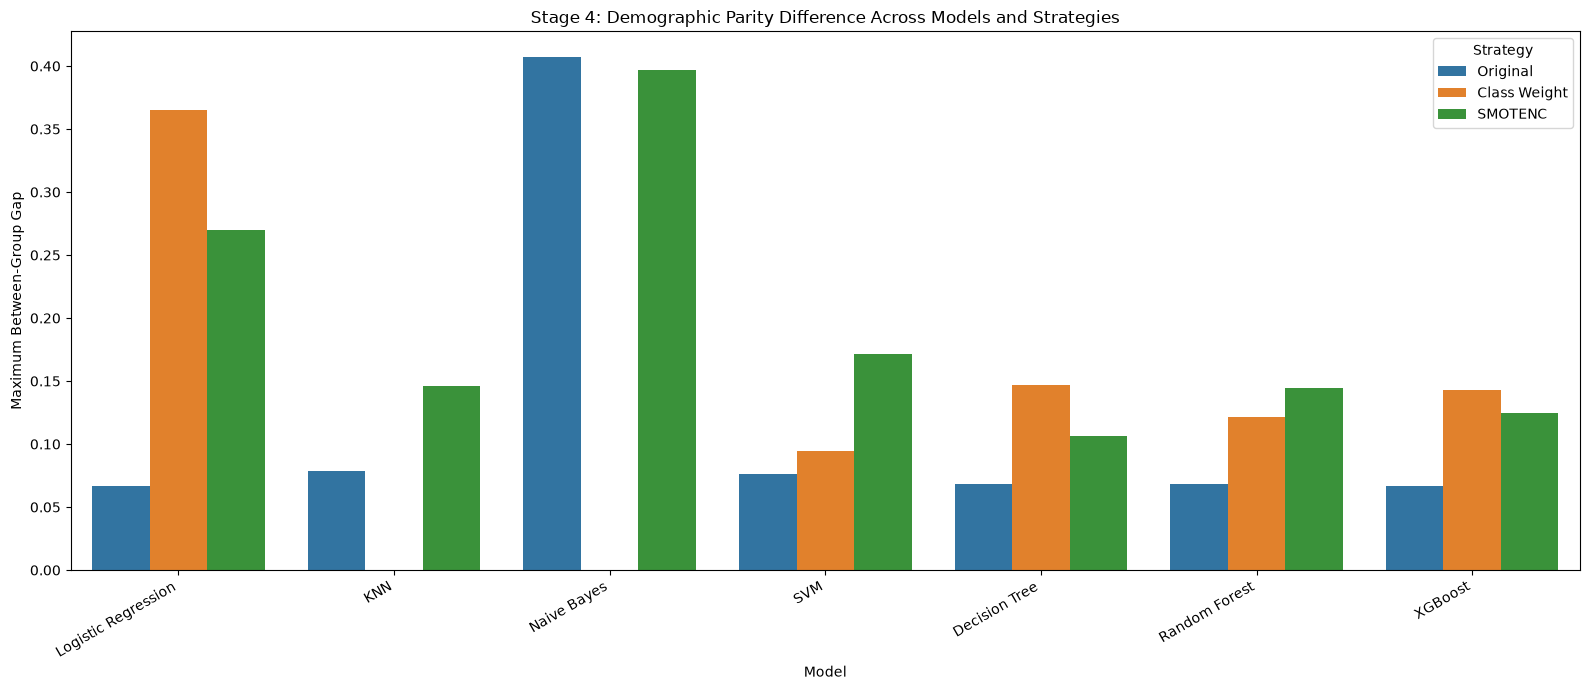

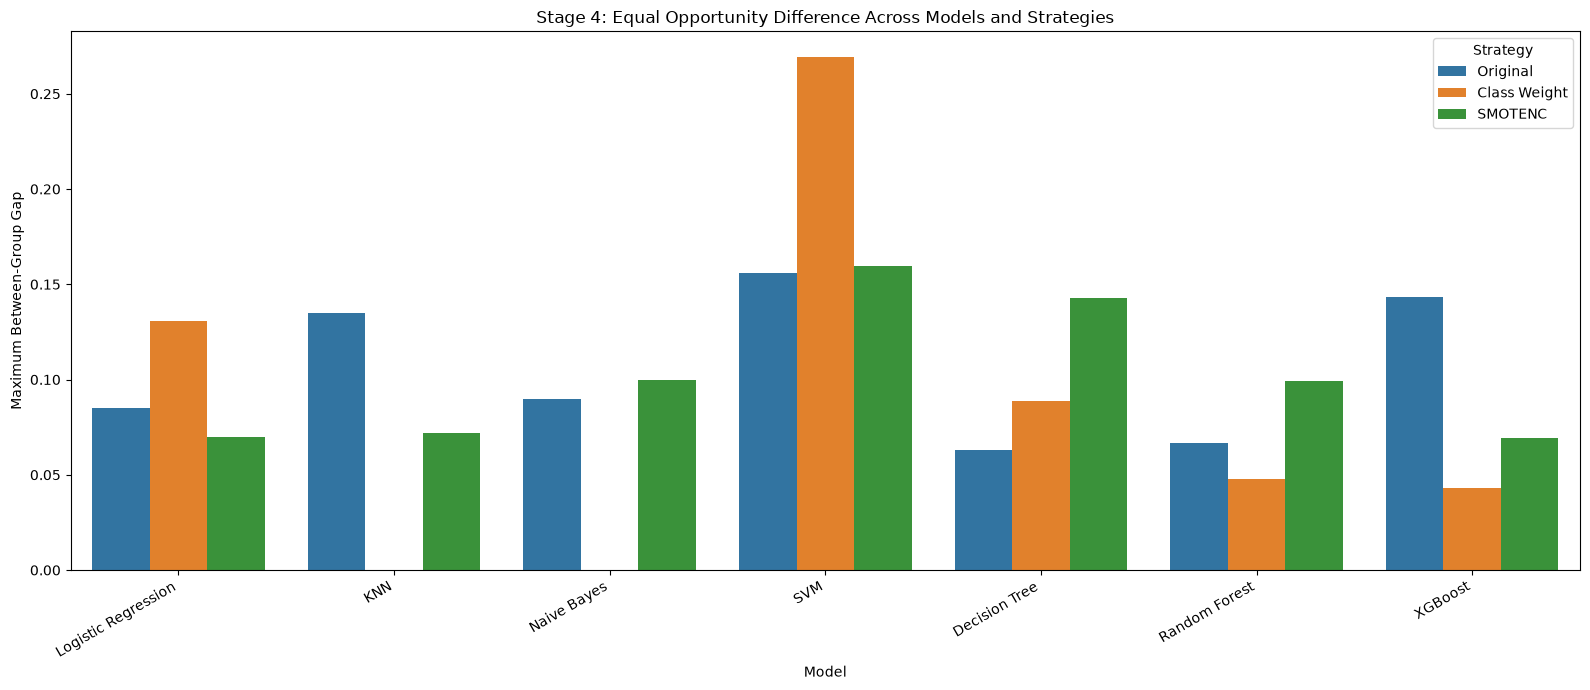

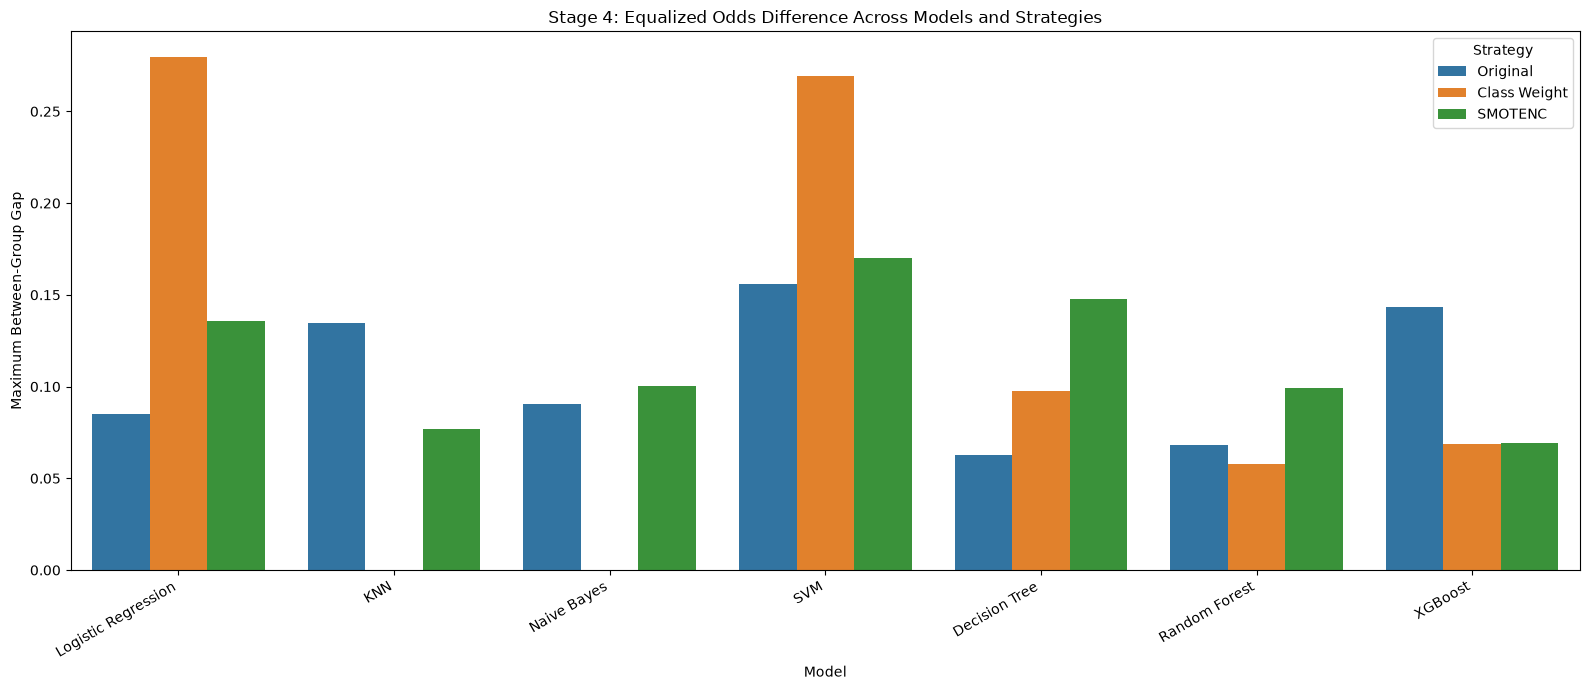

Fairness-gap visualizations generated.


In [16]:

# ==========================================
# Cell 14: Visualize Fairness Gaps
# ==========================================

plot_metrics = [
    "Demographic Parity Difference",
    "Equal Opportunity Difference",
    "Equalized Odds Difference"
]

for metric in plot_metrics:
    plot_data = fairness_gaps_df.dropna(subset=[metric]).copy()

    plt.figure(figsize=(16, 7))

    sns.barplot(
        data=plot_data,
        x="Model",
        y=metric,
        hue="Strategy",
        errorbar=None
    )

    plt.title(f"Stage 4: {metric} Across Models and Strategies")
    plt.xlabel("Model")
    plt.ylabel("Maximum Between-Group Gap")
    plt.xticks(rotation=30, ha="right")
    plt.legend(title="Strategy")
    plt.tight_layout()
    plt.show()

print("Fairness-gap visualizations generated.")


In [17]:

# ==========================================
# Cell 15: Average Fairness Gaps by Strategy
# ==========================================

gap_metrics = [
    "Demographic Parity Difference",
    "Equal Opportunity Difference",
    "FPR Gap",
    "Equalized Odds Difference"
]

strategy_fairness_summary = (
    fairness_gaps_df
    .groupby(["Demographic", "Strategy"])[gap_metrics]
    .agg(["mean", "count"])
    .round(4)
)

display(strategy_fairness_summary)

print("\nInterpretation notes:")
print("- Lower gaps indicate smaller measured between-group disparities.")
print("- NaN gaps are excluded from means, not treated as zero.")
print("- Class Weight has 5 models; Original and SMOTENC have 7.")
print("- These averages are descriptive, not a final fairness ranking.")


Demographic Parity Difference        \
                                                     mean count   
Demographic    Strategy                                           
Age Group      Class Weight                        0.1187     5   
               Original                            0.0480     7   
               SMOTENC                             0.0612     7   
Education      Class Weight                        0.3182     5   
               Original                            0.2495     7   
               SMOTENC                             0.4354     7   
Gender         Class Weight                        0.0565     5   
               Original                            0.0121     7   
               SMOTENC                             0.0332     7   
Gender x Age   Class Weight                        0.1607     5   
               Original                            0.0843     7   
               SMOTENC                             0.1005     7   
Marital Status Class Weight                        0.2165     5   
               Original                            0.2002     7   
               SMOTENC                             0.3408     7   

                            Equal Opportunity Difference       FPR Gap        \
                                                    mean count    mean count   
Demographic    Strategy                                                        
Age Group      Class Weight                       0.1337     5  0.1036     5   
               Original                           0.1077     7  0.0398     7   
               SMOTENC                            0.1055     7  0.0653     7   
Education      Class Weight                          NaN     0  0.2466     5   
               Original                              NaN     0  0.2291     7   
               SMOTENC                               NaN     0  0.3749     7   
Gender         Class Weight                       0.0262     5  0.0568     5   
               Original                           0.0149     7  0.0099     7   
               SMOTENC                            0.0189     7  0.0297     7   
Gender x Age   Class Weight                       0.1879     5  0.1561     5   
               Original                           0.1939     7  0.0665     7   
               SMOTENC                            0.1809     7  0.1181     7   
Marital Status Class Weight                          NaN     0  0.2097     5   
               Original                              NaN     0  0.1947     7   
               SMOTENC                               NaN     0  0.3107     7   

                            Equalized Odds Difference        
                                                 mean count  
Demographic    Strategy                                      
Age Group      Class Weight                    0.1726     5  
               Original                        0.1077     7  
               SMOTENC                         0.1190     7  
Education      Class Weight                       NaN     0  
               Original                           NaN     0  
               SMOTENC                            NaN     0  
Gender         Class Weight                    0.0571     5  
               Original                        0.0161     7  
               SMOTENC                         0.0303     7  
Gender x Age   Class Weight                    0.2341     5  
               Original                        0.1939     7  
               SMOTENC                         0.1931     7  
Marital Status Class Weight                       NaN     0  
               Original                           NaN     0  
               SMOTENC                            NaN     0


Interpretation notes:
- Lower gaps indicate smaller measured between-group disparities.
- NaN gaps are excluded from means, not treated as zero.
- Class Weight has 5 models; Original and SMOTENC have 7.
- These averages are descriptive, not a final fairness ranking.


In [18]:

# ==========================================
# Cell 16: Consolidated Performance-Fairness Report
# ==========================================

# Average available fairness gaps across demographic dimensions
fairness_summary = (
    fairness_gaps_df
    .groupby(["Model", "Strategy"])
    .agg(
        Mean_DP_Gap=("Demographic Parity Difference", "mean"),
        Mean_TPR_Gap=("Equal Opportunity Difference", "mean"),
        Mean_FPR_Gap=("FPR Gap", "mean"),
        Mean_EO_Gap=("Equalized Odds Difference", "mean"),
        Valid_DP_Dimensions=("Demographic Parity Difference", "count"),
        Valid_TPR_Dimensions=("Equal Opportunity Difference", "count"),
        Valid_EO_Dimensions=("Equalized Odds Difference", "count")
    )
    .reset_index()
)

# Join with predictive performance
performance_fairness_df = model_performance_df.merge(
    fairness_summary,
    on=["Model", "Strategy"],
    how="left",
    validate="one_to_one"
)

print("Consolidated performance-fairness report:")
display(
    performance_fairness_df.sort_values(
        ["Strategy", "Model"]
    ).round(4)
)

print("\nReport rows:", len(performance_fairness_df))
assert len(performance_fairness_df) == 19

print("\nReport generated successfully.")


Consolidated performance-fairness report:


,Model,Strategy,Accuracy,F1,Mean_DP_Gap,Mean_TPR_Gap,Mean_FPR_Gap,Mean_EO_Gap,Valid_DP_Dimensions,Valid_TPR_Dimensions,Valid_EO_Dimensions
9,Decision Tree,Class Weight,0.7560,0.5130,0.1467,0.0888,0.1155,0.0975,5,3,3
7,Logistic Regression,Class Weight,0.6782,0.4649,0.3653,0.1307,0.3825,0.2796,5,3,3
10,Random Forest,Class Weight,0.7767,0.5379,0.1216,0.0476,0.1084,0.0578,5,3,3
8,SVM,Class Weight,0.8047,0.4970,0.0941,0.2693,0.0610,0.2693,5,3,3
11,XGBoost,Class Weight,0.7615,0.5203,0.1430,0.0433,0.1054,0.0688,5,3,3
4,Decision Tree,Original,0.8182,0.4564,0.0682,0.0629,0.0664,0.0629,5,3,3
1,KNN,Original,0.8092,0.4428,0.0783,0.1347,0.0534,0.1348,5,3,3
0,Logistic Regression,Original,0.8088,0.3610,0.0666,0.0850,0.0383,0.0850,5,3,3
2,Naive Bayes,Original,0.2913,0.3773,0.4072,0.0898,0.4142,0.0908,5,3,3
5,Random Forest,Original,0.8158,0.4527,0.0682,0.0665,0.0564,0.0681,5,3,3



Report rows: 19

Report generated successfully.


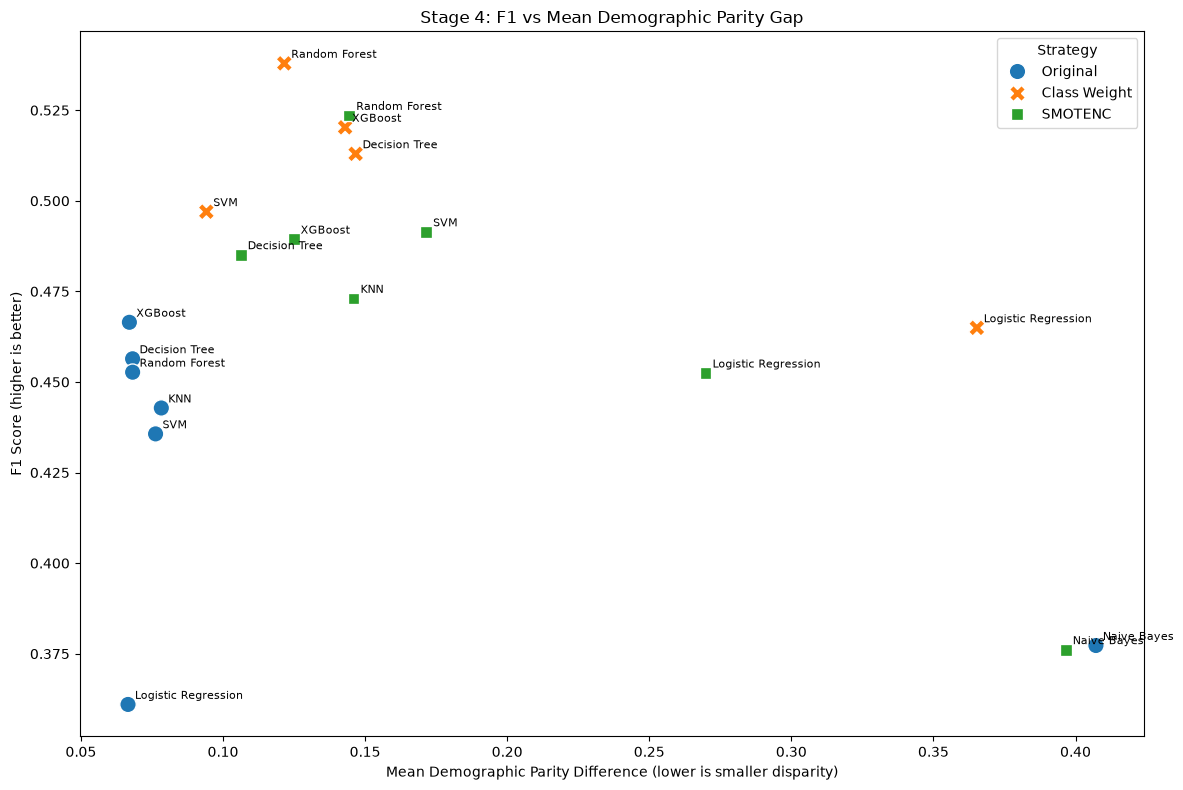

Trade-off plot generated.


In [19]:

# ==========================================
# Cell 17: F1 vs Mean Demographic Parity Gap
# ==========================================

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=performance_fairness_df,
    x="Mean_DP_Gap",
    y="F1",
    hue="Strategy",
    style="Strategy",
    s=140
)

# Label each point with its model
for _, row in performance_fairness_df.iterrows():
    plt.annotate(
        row["Model"],
        (row["Mean_DP_Gap"], row["F1"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8
    )

plt.title("Stage 4: F1 vs Mean Demographic Parity Gap")
plt.xlabel("Mean Demographic Parity Difference (lower is smaller disparity)")
plt.ylabel("F1 Score (higher is better)")
plt.tight_layout()
plt.show()

print("Trade-off plot generated.")


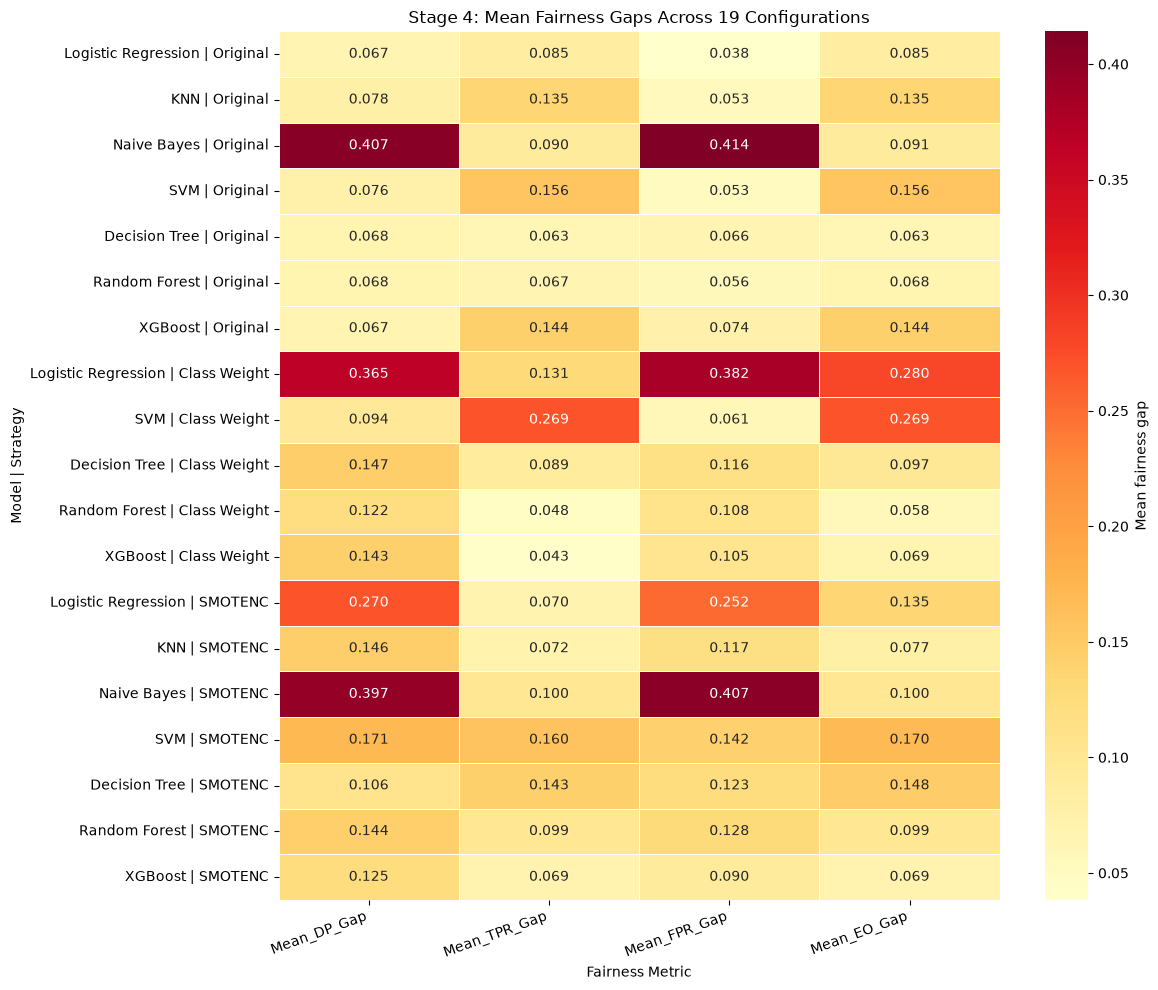

Fairness heatmap generated successfully.


In [21]:

# ==========================================
# Cell 18: Heatmap of Mean Fairness Gaps
# ==========================================

heatmap_metrics = [
    "Mean_DP_Gap",
    "Mean_TPR_Gap",
    "Mean_FPR_Gap",
    "Mean_EO_Gap"
]

heatmap_data = performance_fairness_df.copy()

heatmap_data["Configuration"] = (
    heatmap_data["Model"] + " | " + heatmap_data["Strategy"]
)

# Create a valid matrix: configurations as rows, metrics as columns
heatmap_matrix = heatmap_data.set_index(
    "Configuration"
)[heatmap_metrics]

plt.figure(figsize=(12, 10))

sns.heatmap(
    heatmap_matrix,
    annot=True,
    fmt=".3f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Mean fairness gap"}
)

plt.title("Stage 4: Mean Fairness Gaps Across 19 Configurations")
plt.xlabel("Fairness Metric")
plt.ylabel("Model | Strategy")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("Fairness heatmap generated successfully.")


In [22]:

# ==========================================
# Cell 19: Save Stage 4 Results
# ==========================================

results_path.mkdir(parents=True, exist_ok=True)

group_metrics_path = results_path / "stage4_group_fairness_metrics.csv"
fairness_gaps_path = results_path / "stage4_fairness_gaps.csv"
performance_fairness_path = results_path / "stage4_performance_fairness.csv"

group_fairness_df.to_csv(group_metrics_path, index=False)
fairness_gaps_df.to_csv(fairness_gaps_path, index=False)
performance_fairness_df.to_csv(performance_fairness_path, index=False)

print("Stage 4 results saved successfully.")
print("\nFiles:")
print(group_metrics_path)
print(fairness_gaps_path)
print(performance_fairness_path)

print("\nSaved row counts:")
print("Group-level fairness metrics:", len(group_fairness_df))
print("Fairness gaps:", len(fairness_gaps_df))
print("Performance-fairness report:", len(performance_fairness_df))


Stage 4 results saved successfully.

Files:
D:\TY_Sem1\MLOps\FairXAi\data\results\stage4_group_fairness_metrics.csv
D:\TY_Sem1\MLOps\FairXAi\data\results\stage4_fairness_gaps.csv
D:\TY_Sem1\MLOps\FairXAi\data\results\stage4_performance_fairness.csv

Saved row counts:
Group-level fairness metrics: 532
Fairness gaps: 95
Performance-fairness report: 19


In [ ]:

# Stage 4: Bias Detection and Fairness Audit — Findings and Limitations

## 1. Objective

The objective of Stage 4 was to investigate potential demographic disparities in credit-default predictions across all 7 machine learning models and all 19 applicable model-strategy configurations from Stage 3.

The audit examined five demographic dimensions:
- Gender
- Age Group
- Education
- Marital Status
- Gender × Age (intersectional analysis)

The same 6,000-row test set was used for all configurations.

## 2. Fairness Metrics Evaluated

The following metrics were calculated for each demographic group:

- **True Positive Rate (TPR / Recall):** Proportion of actual defaulters correctly identified.
- **False Positive Rate (FPR):** Proportion of actual non-defaulters incorrectly classified as defaulters.
- **False Negative Rate (FNR):** Proportion of actual defaulters incorrectly classified as non-defaulters.
- **Selection Rate:** Proportion of individuals predicted as defaulters.
- **Demographic Parity Difference:** Maximum difference in selection rates between demographic groups.
- **Equal Opportunity Difference:** Maximum difference in TPR between groups.
- **Equalized Odds Difference:** Maximum of the TPR gap and FPR gap.

Lower fairness gaps indicate smaller measured disparities for the corresponding metric.

## 3. Main Findings

### 3.1 Gender

Gender showed relatively small average disparities under the Original strategy:
- Mean demographic parity difference: 0.0121.
- Mean equal opportunity difference: 0.0149.
- Mean FPR gap: 0.0099.
- Mean equalized odds difference: 0.0161.

The average gaps were higher under Class Weight and SMOTENC. This suggests that changes intended to improve minority-class detection can also change disparities between gender groups.

### 3.2 Age Group

The Original strategy showed lower average gaps than Class Weight and SMOTENC across the reported fairness metrics.

The age-group audit also showed differences in TPR between groups. For example, Random Forest with Original training achieved a TPR of 0.3888 for ages 21–29 and 0.3113 for ages 30–39.

The 60+ test group contained only 76 individuals, so its estimated rates should be interpreted cautiously.

### 3.3 Education

The audit showed substantial differences in selection rates and FPR across education categories.

For example, Random Forest with Original training had a TPR of:
- 0.2938 for Graduate school.
- 0.3525 for University.
- 0.0000 for some small "Other" categories.

These categories had very small sample sizes. Zero observed TPR in a small group does not establish systematic discrimination.

**Undefined TPR and Equalized Odds:** The TPR and FNR were undefined for the Education category `Unknown (0)`, which contained only two test records and no actual defaulters. Consequently, Equal Opportunity Difference and Equalized Odds Difference were undefined for all 19 configurations in the education audit.

These undefined values were retained as NaN rather than replaced with zero.

### 3.4 Marital Status

The audit identified differences in selection rates and FPR between marital-status groups.

For Random Forest with Original training, the "Other (3)" category had a TPR of 0.1667, based on only 12 actual defaulters. The `Unknown (0)` category contained seven individuals and no actual defaulters.

**Undefined TPR and Equalized Odds:** Because the `Unknown (0)` group had no actual defaulters, its TPR and FNR were undefined. Therefore, Equal Opportunity Difference and Equalized Odds Difference were undefined for all 19 configurations in the marital-status audit.

These results must be interpreted cautiously because the smaller categories provide limited evidence for reliable group comparisons.

### 3.5 Gender × Age Intersectional Analysis

The intersectional audit revealed disparities that were not always as visible when considering gender or age separately.

For example, under Random Forest with Original training:
- Female, ages 21–29: TPR = 0.4079.
- Female, ages 30–39: TPR = 0.2915.

Across configurations, the Original strategy had a lower average demographic parity gap than Class Weight and SMOTENC. The results indicate that intersectional comparisons are important when examining potential fairness concerns.

## 4. Comparison of Imbalance Strategies

The audit showed that the three strategies did not produce the same fairness outcomes.

- **Original:** Generally showed smaller average gaps for Gender and Age Group, with relatively small gaps for several models.
- **Class Weight:** Improved default detection in Stage 3 for several models, but increased fairness gaps for some configurations and demographic dimensions.
- **SMOTENC:** Did not consistently reduce disparities. Its effects varied across models and fairness metrics.

No strategy was uniformly best across all demographic dimensions and predictive metrics.

## 5. Performance–Fairness Trade-off

The combined performance-fairness analysis showed that predictive performance and demographic fairness must be evaluated together.

Examples include:
- Random Forest with Class Weight achieved an F1 score of 0.5379, the highest among the evaluated configurations, while its mean demographic parity gap was 0.1216.
- Decision Tree with Original training achieved an accuracy of 0.8182 and a mean demographic parity gap of 0.0682.
- Naive Bayes showed very large mean demographic parity and FPR gaps under Original and SMOTENC, alongside poor predictive performance.

These results illustrate why accuracy or F1 alone is insufficient for assessing a credit-risk model.

The reported mean fairness gaps average the available demographic dimensions. TPR and equalized-odds summaries use only the three dimensions where these metrics were defined. These averages are descriptive and should not be treated as a complete fairness score.

## 6. Limitations

1. **Single test split:** The audit used one 6,000-row test set. The measured disparities may vary on other samples.
2. **Small demographic groups:** Some education, marital-status, age, and intersectional groups had limited sample sizes, leading to unstable rates.
3. **Undefined rates:** Education `Unknown (0)` and Marital Status `Unknown (0)` had no actual defaulters in the test set. Their TPR and FNR were undefined, so equal-opportunity and equalized-odds gaps could not be calculated for those demographic dimensions.
4. **Descriptive comparisons:** The audit did not establish statistical significance or calculate confidence intervals for the fairness gaps.
5. **Metric dependence:** Fairness conclusions depend on the chosen metric. Demographic parity, equal opportunity, and equalized odds measure different aspects of group disparities.
6. **Association is not causation:** Observed disparities do not establish that a sensitive attribute caused the predictions or prove unlawful discrimination.
7. **No mitigation tested yet:** This stage identifies potential fairness concerns; it does not establish that a mitigation method will successfully address them.

## 7. Stage 4 Conclusion

Stage 4 successfully evaluated all 19 model-strategy configurations across Gender, Age Group, Education, Marital Status, and Gender × Age.

The audit identified potential demographic disparities, particularly for some education, marital-status, and intersectional comparisons. The results also showed that class weighting and SMOTENC, despite improving default detection for several models, did not consistently reduce fairness gaps.

The findings support a multi-metric approach that considers predictive performance, false-positive and false-negative rates, and demographic fairness together.

The results should be interpreted as evidence of **potential demographic disparity**, not proof of discrimination. The next stage will investigate fairness mitigation approaches and evaluate whether disparities can be reduced while maintaining useful predictive performance across all applicable models and strategies.
